In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [ ]:
df=pd.read_csv('diabetes_prediction_dataset.csv')

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [ ]:
df['bmi']

,bmi
0,25.19
1,27.32
2,27.32
3,23.45
4,20.14
...,...
99995,27.32
99996,17.37
99997,27.83
99998,35.42


<Figure size 1000x1200 with 0 Axes>

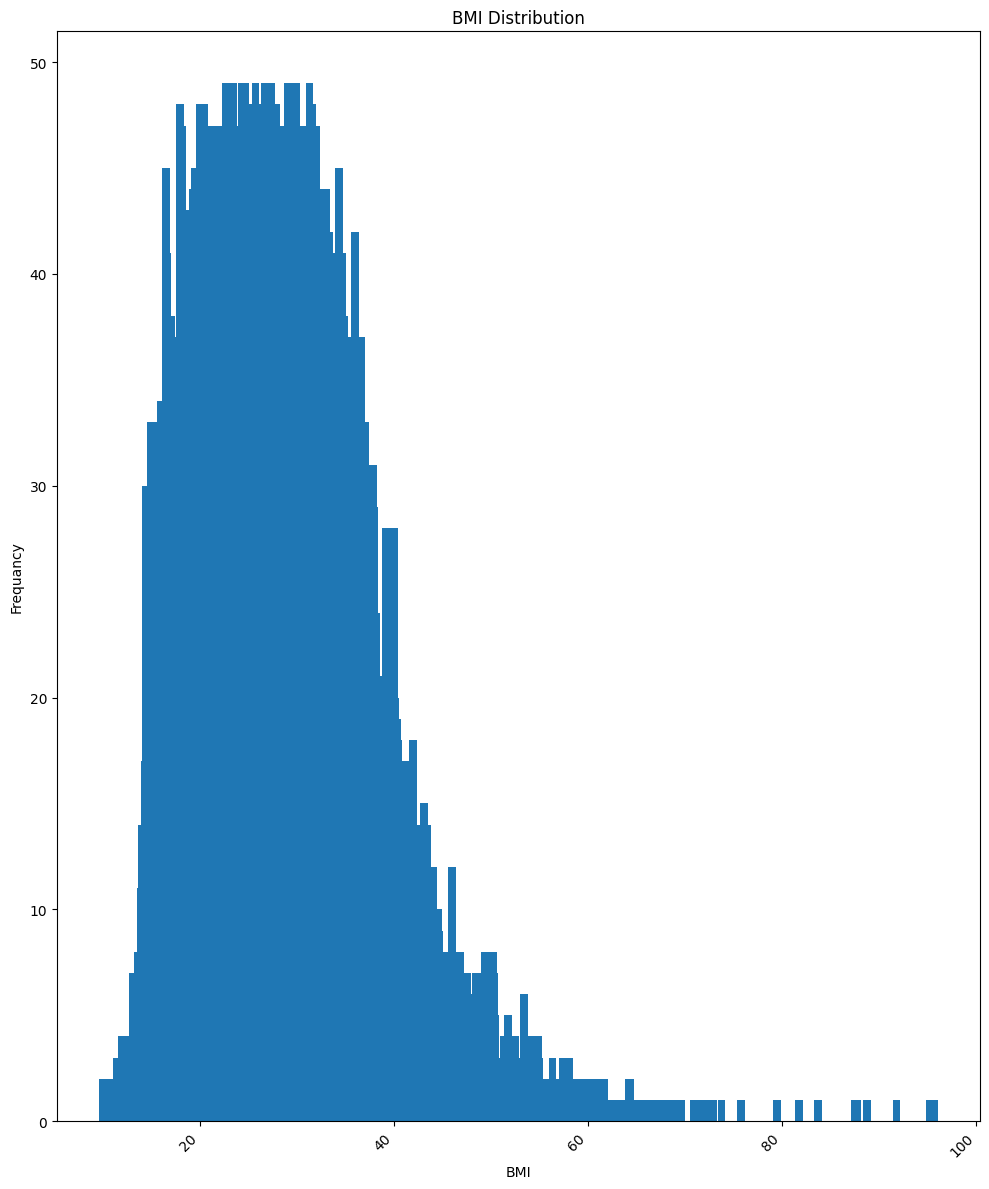

In [ ]:
plt.figure(figsize=(10, 12))
plt.figure(figsize=(10, 12))
bmi_counts = df['bmi'].value_counts()

# Filter bmi_counts and update index accordingly
filtered_bmi_counts = bmi_counts[bmi_counts.values < 50]

# Now use filtered_bmi_counts.index and filtered_bmi_counts.values
plt.bar(filtered_bmi_counts.index, filtered_bmi_counts.values)
plt.xlabel('BMI')
plt.ylabel('Frequancy')
plt.title('BMI Distribution')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent labels from overlapping
plt.show()

In [ ]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [ ]:
df[df['gender']=='Other'].count()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [ ]:
df = df.drop(df[df['gender'] == 'Other'].index)

In [ ]:
df[df['gender']=='Other'].count()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [ ]:
df['gender'].unique()

array([0, 1])

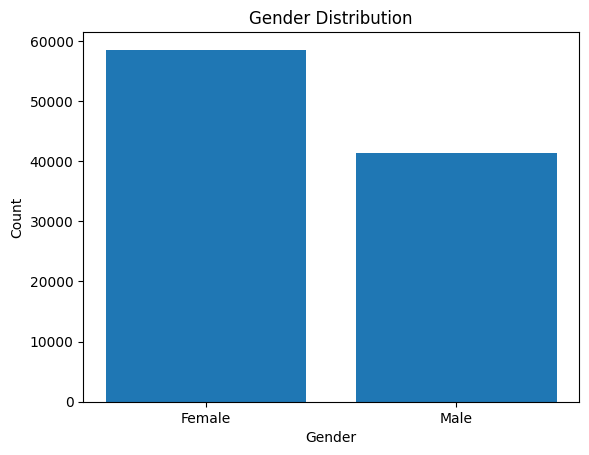

In [ ]:
plt.bar(df['gender'].unique(),df['gender'].value_counts())
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Distribution')
plt.show()

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


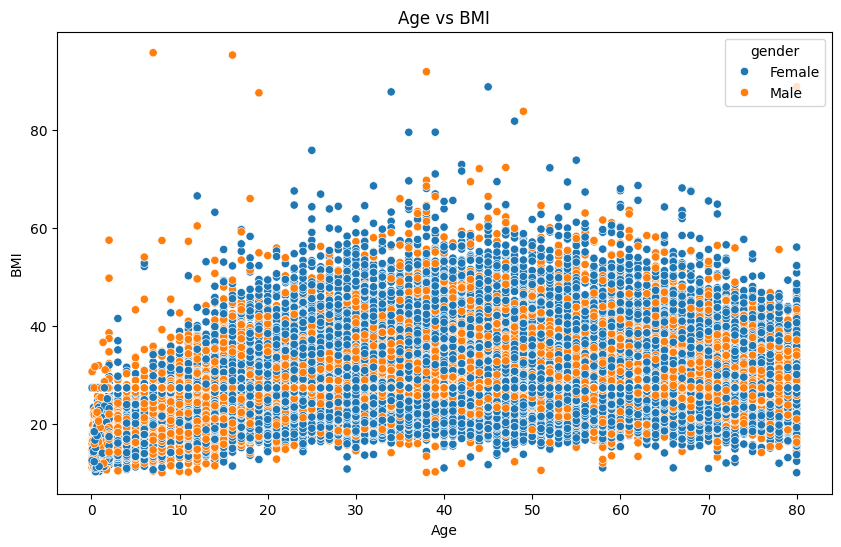

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='age',y='bmi',data=df,hue='gender')
plt.xlabel('Age')
plt.ylabel('BMI')
plt.title('Age vs BMI')
plt.show()

In [ ]:
df.shape

(99982, 9)

In [ ]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,99982.000000,99982.000000,99982.000000,99982.000000,99982.000000,99982.000000,99982.000000
mean,41.888076,0.074863,0.039427,27.320757,5.527529,138.057810,0.085015
std,22.517206,0.263172,0.194610,6.636853,1.070665,40.709469,0.278906
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.000000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.000000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.000000,1.000000,95.690000,9.000000,300.000000,1.000000


In [ ]:
df[df['smoking_history']=='No Info']

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
14,Female,76.0,0,0,No Info,27.32,5.0,160,0
15,Male,78.0,0,0,No Info,27.32,6.6,126,0
18,Female,42.0,0,0,No Info,27.32,5.7,80,0
...,...,...,...,...,...,...,...,...,...
99989,Female,26.0,0,0,No Info,27.32,5.0,158,0
99990,Male,39.0,0,0,No Info,27.32,6.1,100,0
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0


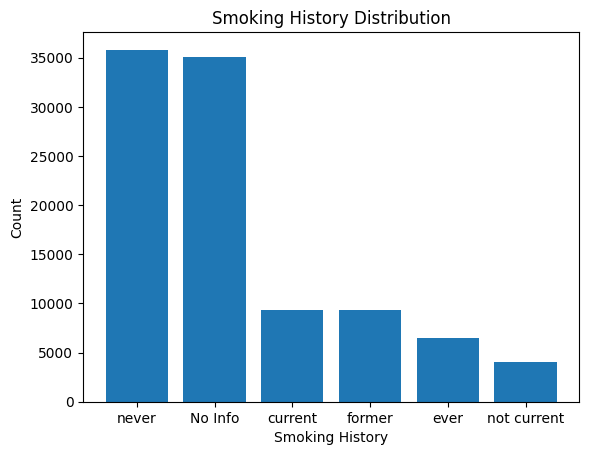

In [ ]:
plt.bar(df['smoking_history'].unique(),df['smoking_history'].value_counts())
plt.xlabel('Smoking History')
plt.ylabel('Count')
plt.title('Smoking History Distribution')
plt.show()

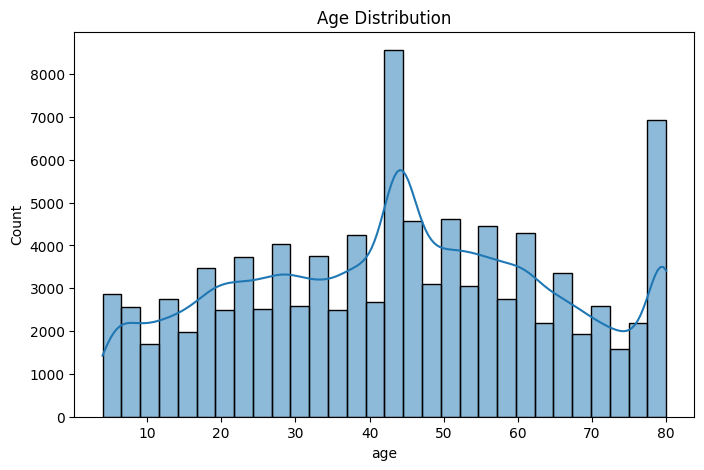

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

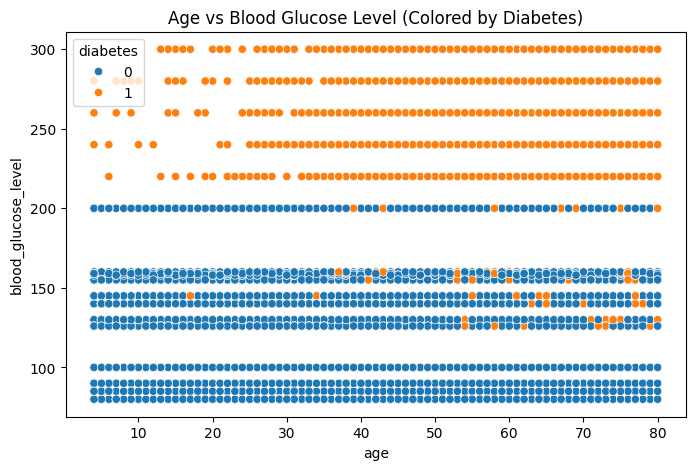

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df['age'], y=df['blood_glucose_level'], hue=df['diabetes'])
plt.title("Age vs Blood Glucose Level (Colored by Diabetes)")
plt.show()


In [ ]:
df['smoking_history'].unique()

array(['never', 'No Info', 'current', 'former', 'ever', 'not current'],
      dtype=object)

In [ ]:
LabelEncoder = LabelEncoder()
df['gender'] = LabelEncoder.fit_transform(df['gender'])
df['smoking_history'] = LabelEncoder.fit_transform(df['smoking_history'])


In [ ]:
df['smoking_history'].unique()

array([4, 0, 1, 3, 2, 5])

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,6.6,140,0
1,0,54.0,0,0,0,27.32,6.6,80,0
2,1,28.0,0,0,4,27.32,5.7,158,0
3,0,36.0,0,0,1,23.45,5.0,155,0
4,1,76.0,1,1,1,20.14,4.8,155,0


In [ ]:
df['diabetes'].unique()

array([0, 1])

<Axes: >

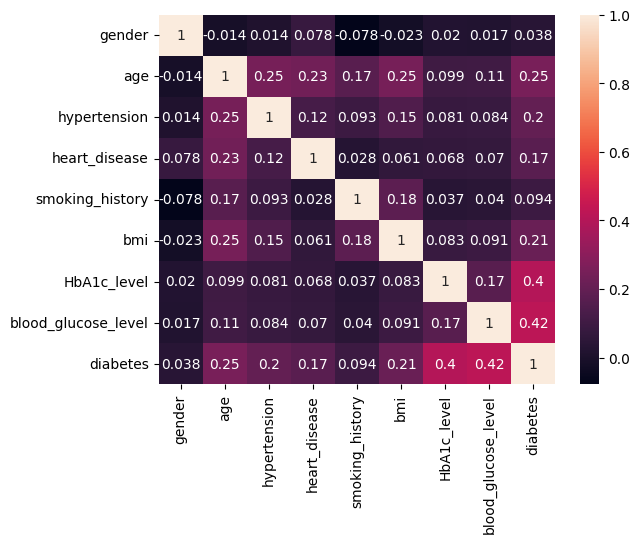

In [ ]:
sns.heatmap(df.corr(),annot=True)

In [ ]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

In [ ]:
y

,diabetes
0,0
1,0
2,0
3,0
4,0
...,...
99995,0
99996,0
99997,0
99998,0


In [ ]:
y.isnull().sum()

0

In [ ]:
scaler = StandardScaler() # imbalance in how the model learns.
X_scaled = scaler.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [ ]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print(f"Confusion Matrix:\n{conf_matrix}")
print(f"Classification Report:\n{class_report}")

Accuracy: 0.96
Confusion Matrix:
[[18064   158]
 [  653  1122]]
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18222
           1       0.88      0.63      0.73      1775

    accuracy                           0.96     19997
   macro avg       0.92      0.81      0.86     19997
weighted avg       0.96      0.96      0.96     19997



In [ ]:
!pip install mlflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.3/28.3 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.0/6.0 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.6/233.6 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.8/147.8 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.0/85.0 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 637.5/637.5 kB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.2/203.2 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.6/78.6 kB 7.0 MB/s eta 0:00:00


In [ ]:

!pip install mlflow


import mlflow
from google.colab import files
import pickle


mlflow.set_tracking_uri("file:///content/mlruns")
mlflow.set_experiment("Fuzzy Logic Diabetes Risk")

def bmi_membership(bmi):
    if bmi < 18.5:
        return "underweight"
    elif 18.5 <= bmi < 25:
        return "normal"
    elif 25 <= bmi < 30:
        return "overweight"
    else:
        return "obese"

def hba1c_membership(hba1c):
    if hba1c < 5.7:
        return "low"
    elif 5.7 <= hba1c < 6.5:
        return "normal"
    else:
        return "high"

def age_membership(age):
    if age < 35:
        return "young"
    elif 35 <= age < 60:
        return "middle-aged"
    else:
        return "old"

def blood_glucose_membership(blood_glucose):
    if blood_glucose < 100:
        return "low"
    elif 100 <= blood_glucose < 130:
        return "normal"
    else:
        return "high"

def logistic_output_membership(logistic_output):
    if logistic_output < 0.5:
        return "low_risk"
    else:
        return "high_risk"

# Define fuzzy rules
def fuzzy_rules(bmi_category, hba1c_category, age_category, blood_glucose_category, logistic_output_category):
    if (bmi_category in ["overweight", "obese"] and hba1c_category == "high" and logistic_output_category == "high_risk"):
        return "high"
    elif (age_category in ["middle-aged", "old"] and blood_glucose_category in ["normal", "high"] and logistic_output_category == "high_risk"):
        return "high"
    elif (bmi_category == "normal" and hba1c_category == "normal" and logistic_output_category == "low_risk"):
        return "low"
    else:
        return "medium"

with mlflow.start_run():
    bmi_value = 28.5 ##EXAMPLE INPUTS
    hba1c_value = 6.7
    age_value = 45
    blood_glucose_value = 120
    logistic_output_value = 0.6

    mlflow.log_param("BMI", bmi_value)
    mlflow.log_param("HbA1c", hba1c_value)
    mlflow.log_param("Age", age_value)
    mlflow.log_param("Blood Glucose", blood_glucose_value)
    mlflow.log_param("Logistic Output", logistic_output_value)

    bmi_category = bmi_membership(bmi_value)
    hba1c_category = hba1c_membership(hba1c_value)
    age_category = age_membership(age_value)
    blood_glucose_category = blood_glucose_membership(blood_glucose_value)
    logistic_output_category = logistic_output_membership(logistic_output_value)

    mlflow.log_param("BMI Category", bmi_category)
    mlflow.log_param("HbA1c Category", hba1c_category)
    mlflow.log_param("Age Category", age_category)
    mlflow.log_param("Blood Glucose Category", blood_glucose_category)
    mlflow.log_param("Logistic Output Category", logistic_output_category)

    # Apply fuzzy rules
    diabetes_risk = fuzzy_rules(bmi_category, hba1c_category, age_category, blood_glucose_category, logistic_output_category)

    # Log final result
    mlflow.log_param("Diabetes Risk", diabetes_risk)

    # Print result
    print(f"Diabetes Risk: {diabetes_risk}")

    # Collect all the parameters and results into a dictionary
    experiment_results = {
        "BMI": bmi_value,
        "HbA1c": hba1c_value,
        "Age": age_value,
        "Blood Glucose": blood_glucose_value,
        "Logistic Output": logistic_output_value,
        "BMI Category": bmi_category,
        "HbA1c Category": hba1c_category,
        "Age Category": age_category,
        "Blood Glucose Category": blood_glucose_category,
        "Logistic Output Category": logistic_output_category,
        "Diabetes Risk": diabetes_risk
    }

# Save the dictionary as a .pkl file
with open("modified_model.pkl", "wb") as f:
    pickle.dump(experiment_results, f)

# Download the .pkl file
files.download("modified_model.pkl")


Diabetes Risk: high


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>